# Black-box attack matrix (V2)

"Who attacks whom?" -- source-group x target-group matrix of the configured metric.

Recommended default: architecture x architecture, `inter_architecture`,
`Transfer ASR`, `blacklist_contains=("HQuanv",)` (the `architecture_main` template).

# Black-box transfer analytics V2 -- shared configuration

All four `attacksv2_*` notebooks use the same `AttacksV2Config` object and the same
filtering/blacklist/aggregation backend (`analytics.attacks.attacksv2_transfer_tools`),
so the scatter, matrix, top-k rankings, and asymmetry tables are directly comparable.

Key knobs:

- `metric`: `"Transfer ASR"` (default), `"Transfer Robust Accuracy"`, `"Accuracy Drop"`,
  `"Mean Confidence Drop"`, `"Mean Margin Drop"`, ... Ranking direction is handled
  automatically (e.g. for robust-target rankings, lower ASR but *higher* robust accuracy
  is more robust).
- `source_grain` / `target_grain`: `"family"`, `"architecture"`, or `"variant"`.
- `comparison_mode`:
  - `"inter_variant"`: exclude exact same variant/model only.
  - `"inter_architecture"`: exclude same-architecture pairs.
  - `"inter_family"`: exclude same-family pairs.
- `variant_aggregate_mode`: `"none"` (variant grain only), `"mean"`, `"median"`,
  `"best_damage"`, `"best_robust"`, `"manual_representative"` (with
  `manual_representatives=((arch_substring, variant_substring), ...)`).
- `architecture_aggregate_mode`: `"mean"`, `"median"`, `"best_damage"`, `"best_robust"`.
- `split_quantum_ansatz_as_architecture`: turn ansatz variants into pseudo-architectures
  (`VQM-Basic`, `VQM-Strong`, `HVQL-Random`, ...) consistently across all views.
- `blacklist_exact` / `blacklist_contains` (e.g. `("HQuanv",)`).
- `selected_rows` / `selected_columns`: explicit group selection + ordering.
- `top_k` (default 3) and `output_dir` (default `outputs/attacksv2_transfer/`).

Templates: `architecture_main`, `architecture_with_variants`, `variant_spread`,
`family_synthesis`, `ansatz_split`, `topk_main_architecture` -- see `list_v2_templates()`.


In [2]:
from pathlib import Path
import sys

try:
    from analytics.paths import find_project_root, output_dir
except ModuleNotFoundError:
    # Allow running the notebook from anywhere inside the repo.
    repo_root = Path.cwd()
    while repo_root != repo_root.parent and not (repo_root / "src").exists():
        repo_root = repo_root.parent
    sys.path.insert(0, str(repo_root / "src"))
    from analytics.paths import find_project_root, output_dir

from analytics.attacks.attacksv2_transfer_tools import (
    AttacksV2Config,
    V2_TEMPLATES,
    get_v2_template,
    list_v2_templates,
    v2_output_dir,
    metric_direction_notes,
    load_or_build_pair_metrics,
    export_table,
    export_figure,
    build_source_target_scatter,
    plot_source_target_scatter,
    build_attack_matrix,
    plot_attack_matrix,
    build_topk_instances,
    summarize_recurring,
    build_recurring_damaging_sources,
    build_recurring_robust_targets,
    plot_topk_ranking,
    build_directional_pair_table,
    plot_directional_asymmetry_bars,
    run_smoke_test,
)

ROOT = find_project_root()
PAIR_METRICS_CACHE = output_dir(ROOT, "attack_transfer_role_tables") / "pair_metrics.csv"


In [3]:
# Template selection -- run list_v2_templates() to inspect all presets.
TEMPLATE_NAME = "architecture_main"
CONFIG = get_v2_template(TEMPLATE_NAME)
list_v2_templates()


,template,source_grain,target_grain,comparison_mode,metric,top_k,variant_aggregate_mode,architecture_aggregate_mode,split_ansatz_as_architecture,include_no_entangling_as_ansatz,...,target_architecture_filter,source_contains,target_contains,blacklist_exact,split_quantum_ansatz_as_architecture,selected_rows,selected_columns,scatter_display_mode,manual_representatives,output_dir
0,architecture_main,architecture,architecture,inter_architecture,Transfer ASR,3,mean,mean,False,True,...,None,None,None,(),False,None,None,architectures_only,(),None
1,architecture_with_variants,architecture,architecture,inter_architecture,Transfer ASR,3,mean,mean,False,True,...,None,None,None,(),False,None,None,both,(),None
2,variant_spread,variant,variant,inter_architecture,Transfer ASR,3,mean,mean,False,True,...,None,None,None,(),False,None,None,variants_only,(),None
3,family_synthesis,family,family,inter_family,Transfer ASR,3,mean,mean,False,True,...,None,None,None,(),False,None,None,architectures_only,(),None
4,ansatz_split,architecture,architecture,inter_architecture,Transfer ASR,3,mean,mean,True,True,...,None,None,None,(),True,None,None,architectures_only,(),None
5,topk_main_architecture,architecture,architecture,inter_architecture,Transfer ASR,3,mean,mean,False,True,...,None,None,None,(),False,None,None,architectures_only,(),None


In [4]:
# Optional overrides -- uncomment and edit, then re-run the cells below.
CONFIG = CONFIG.with_updates(
    # metric="Transfer Robust Accuracy",
    # source_grain="variant",
    # target_grain="variant",
    # comparison_mode="inter_family",
    # variant_aggregate_mode="best_damage",
    # architecture_aggregate_mode="mean",
    # split_quantum_ansatz_as_architecture=True,
    # blacklist_exact=("Quantum/VQM/some_variant",),
    # blacklist_contains=("HQuanv",),
    # selected_rows=("Quantum/VQM", "Classical/CNN"),
    # selected_columns=None,
    # top_k=3,
    # output_dir=None,  # defaults to outputs/attacksv2_transfer/
)
CONFIG


AttacksV2Config(source_grain='architecture', target_grain='architecture', comparison_mode='inter_architecture', metric='Transfer ASR', top_k=3, variant_aggregate_mode='mean', architecture_aggregate_mode='mean', split_ansatz_as_architecture=False, include_no_entangling_as_ansatz=True, model_blacklist=(), blacklist_contains=('HQuanv',), source_family_filter=None, target_family_filter=None, source_architecture_filter=None, target_architecture_filter=None, source_contains=None, target_contains=None, blacklist_exact=(), split_quantum_ansatz_as_architecture=False, selected_rows=None, selected_columns=None, scatter_display_mode='architectures_only', manual_representatives=(), output_dir=None)

In [5]:
pair_df = load_or_build_pair_metrics(pair_metrics_cache=PAIR_METRICS_CACHE, rebuild=False)
print(f"Loaded pair metrics: {pair_df.shape[0]:,} rows x {pair_df.shape[1]:,} columns")
metric_direction_notes(CONFIG.metric)


Loaded pair metrics: 1,089 rows x 24 columns


{'source': 'higher Transfer ASR = more damaging source',
 'target': 'higher Transfer ASR = more vulnerable target',
 'robust_target': 'lower Transfer ASR = more robust target'}

In [6]:
matrix = build_attack_matrix(pair_df, CONFIG)
matrix

target_group,Classical/CNN,Classical/MLP,Classical/MLPMixer,Classical/ResNet18,Hybrid/HPVQL,Hybrid/HQE,Hybrid/HVQL,Hybrid/HVQM,Quantum/VQM
source_group,,,,,,,,,
Classical/CNN,NaN,0.837322,0.792040,0.756476,0.708802,0.805575,0.721646,0.698172,0.649982
Classical/MLP,0.780563,NaN,0.756354,0.728767,0.679194,0.804776,0.689919,0.693272,0.662308
Classical/MLPMixer,0.659569,0.731573,NaN,0.760538,0.650599,0.673283,0.667894,0.617805,0.545941
Classical/ResNet18,0.677878,0.750405,0.729538,NaN,0.696650,0.678657,0.708738,0.657511,0.550858
Hybrid/HPVQL,0.655549,0.724174,0.731059,0.762648,NaN,0.655378,0.724581,0.626180,0.536984
Hybrid/HQE,0.510084,0.558253,0.577079,0.642399,0.445687,NaN,0.480666,0.437968,0.430798
Hybrid/HVQL,0.642505,0.709385,0.726244,0.761206,0.692973,0.633422,NaN,0.626720,0.527511
Hybrid/HVQM,0.643164,0.715249,0.729950,0.752337,0.654888,0.641751,0.671408,NaN,0.597802
Quantum/VQM,0.647389,0.731260,0.745898,0.760525,0.662245,0.666327,0.678820,0.681994,NaN


In [7]:
OUT_DIR = v2_output_dir("matrix", CONFIG)
name = f"matrix__{CONFIG.slug()}"
paths = export_table(matrix, OUT_DIR, name, index=True, latex=True)
paths

{'csv': WindowsPath('C:/Users/fwilh/Desktop/QB-PIER/outputs/attacksv2_transfer/matrix/matrix__architecture_to_architecture__inter_architecture__transfer_asr__vagg-mean.csv'),
 'tex': WindowsPath('C:/Users/fwilh/Desktop/QB-PIER/outputs/attacksv2_transfer/matrix/matrix__architecture_to_architecture__inter_architecture__transfer_asr__vagg-mean.tex')}

{'png': WindowsPath('C:/Users/fwilh/Desktop/QB-PIER/outputs/attacksv2_transfer/matrix/matrix__architecture_to_architecture__inter_architecture__transfer_asr__vagg-mean.png'),
 'pdf': WindowsPath('C:/Users/fwilh/Desktop/QB-PIER/outputs/attacksv2_transfer/matrix/matrix__architecture_to_architecture__inter_architecture__transfer_asr__vagg-mean.pdf')}

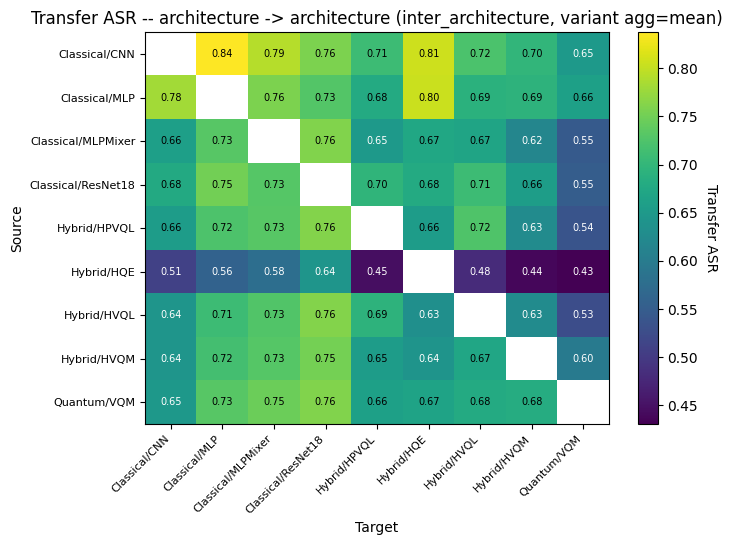

In [8]:
fig, ax = plot_attack_matrix(
    matrix,
    CONFIG,
    title=(f"{CONFIG.metric} -- {CONFIG.source_grain} -> {CONFIG.target_grain} "
           f"({CONFIG.comparison_mode}, variant agg={CONFIG.variant_aggregate_mode})"),
    annotate=True,
)
export_figure(fig, OUT_DIR, name)

In [9]:
# Synthetic-data smoke test: verifies scatter, matrix, top-k summaries, and
# the directional asymmetry table all build with the shared backend.
_ = run_smoke_test(verbose=True)


[smoke] scatter: 14 rows x 13 cols
[smoke] matrix: 5 rows x 5 cols
[smoke] topk_long_damaging_sources_for_targets: 15 rows x 13 cols
[smoke] topk_long_robust_targets_for_sources: 15 rows x 13 cols
[smoke] topk_long_least_damaging_sources_for_targets: 15 rows x 13 cols
[smoke] topk_long_least_robust_targets_for_sources: 15 rows x 13 cols
[smoke] recurring_damaging_sources: 5 rows x 13 cols
[smoke] recurring_robust_targets: 5 rows x 13 cols
[smoke] asymmetry: 10 rows x 14 cols
[smoke] matrix_ansatz: 9 rows x 9 cols
[smoke] scatter_family: 3 rows x 13 cols
[smoke] all checks passed
